In [ ]:
# === LOAD: locate repo and load `sessions` with all_data_df ===
import sys, pickle
from pathlib import Path
import pandas as pd

# Try to discover the repo root from the current notebook location
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    # fallback to your known absolute path
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

# Make package importable (optional, but matches your pat   tern)
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

# Optional sanity check for the package
try:
    import importlib; importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

# Default PKL path from your earlier snippet
PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"

# Fallback: search for a suitable PKL if the default is missing
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    # pick the most recent
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

with PKL.open("rb") as f:
    sessions = pickle.load(f)

print(f"Loaded {len(sessions)} sessions from {PKL}")

# Keep only sessions that actually have non-empty all_data_df
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

# Quick peek
if sessions:
    s0 = sessions[0]
    sid  = getattr(s0, "session_id", "<no id>")
    geno = (getattr(s0, "metadata", {}) or {}).get("genotype", "UNK")
    print(f"Example session: {sid} | genotype={geno}")
    display(s0.all_data_df.head())
else:
    raise RuntimeError("No usable sessions found; check your pickle or preprocessing.")


Using fallback pickle: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls_datta.pkl


/tmp/ipykernel_203761/873917099.py:42: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  sessions = pickle.load(f)


Loaded 19 sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls_datta.pkl
Usable sessions with all_data_df: 19
Example session: 2024-12-13T12_20_06_bottom_left | genotype=WT


,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset,...,signal_0_zscore_datta,signal_1_dff,signal_1_zscore,signal_1_zscore_datta,signal_2_dff,signal_2_zscore,signal_2_zscore_datta,signal_3_dff,signal_3_zscore,signal_3_zscore_datta
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.051823,199.522437,-1.122018,0.000000,0.000000,56,69517,WT,True,...,0.758224,-0.456758,-0.635931,-0.340642,-0.342478,-0.795487,-0.997753,-0.565258,-0.636459,-0.989441
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,166.903142,199.062367,-1.122018,0.012100,14.504940,56,69518,WT,False,...,0.936413,-0.457280,-0.642150,-0.387259,-0.341230,-0.789986,-0.917169,-0.565216,-0.636034,-0.906803
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.223306,199.104034,-1.122018,0.027302,9.685929,56,69519,WT,False,...,1.114601,-0.457802,-0.648369,-0.433876,-0.339982,-0.784485,-0.836585,-0.565174,-0.635609,-0.824166
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.995061,199.575542,-1.136146,0.046672,27.131755,56,69520,WT,False,...,1.292789,-0.458323,-0.654588,-0.480492,-0.338734,-0.778983,-0.756001,-0.565133,-0.635184,-0.741529
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.522242,201.069801,-1.122018,0.068494,47.535846,56,69521,WT,False,...,1.578211,-0.457493,-0.644689,-0.433324,-0.338548,-0.778165,-0.747396,-0.563833,-0.621913,-0.615242


Scanning 19 sessions...
Plotting 3x2 Grid...


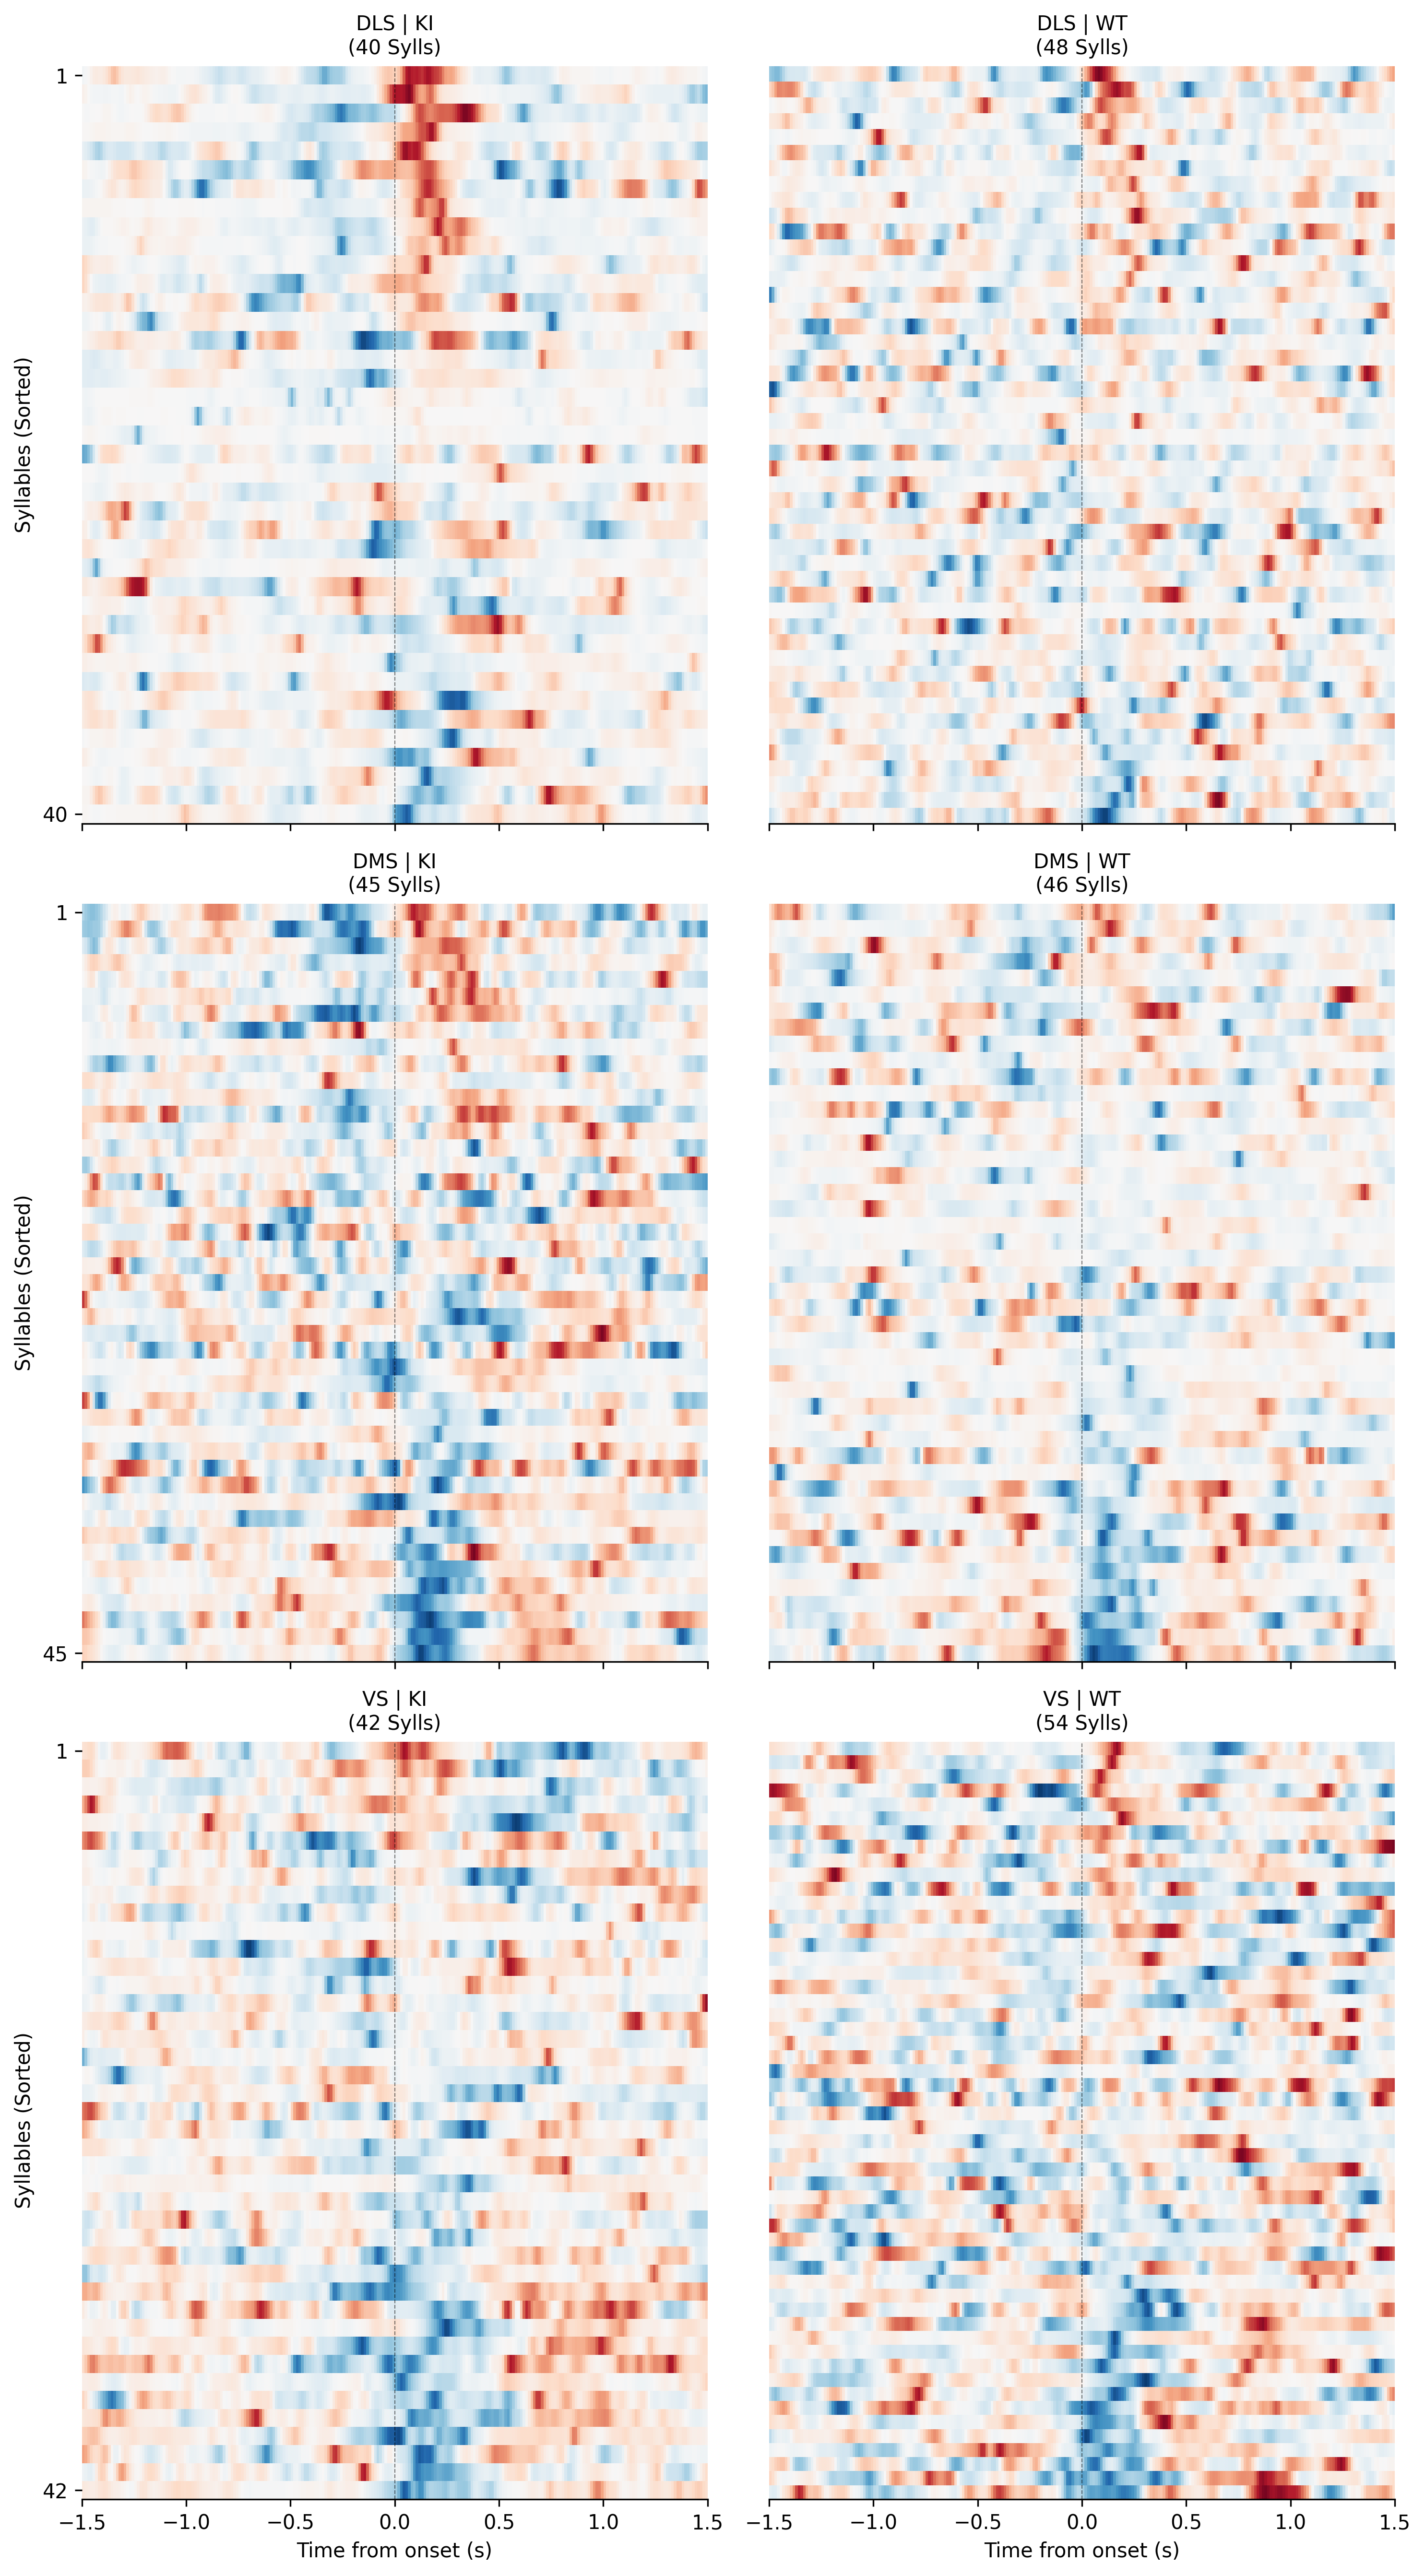

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from scipy.ndimage import gaussian_filter1d
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
# --- TIME & WINDOWING ---
WINDOW_SECONDS = 1.5       # +/- 1.5s around onset
SHUFFLE_JITTER_SEC = 2.0   # +/- 2.0s jitter
N_SHUFFLES = 20            # Efficient shuffling

# --- FILTERS ---
MIN_TRIALS = 100           # Drop rare syllables
TARGET_ORIG_LETTER = "G"   
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}

# --- VISUALIZATION ---
CMAP = "RdBu_r"            
BIN_COUNT = 100            # Time resolution (bins across window)

# --- THE "PRETTY" KNOBS ---
# 1. Smooth the time trace? (Sigma=1.0 is mild, 2.0 is smooth)
# This replaces "blocky" time bins with smooth curves.
SIGMA_TIME_SMOOTHING = 1.0 

# 2. Normalize each row? (True = Scale Max Abs to 1.0)
# This makes every syllable visible, regardless of signal strength.
ROW_WISE_NORM = True       

# ==========================================
# 2. HELPER: BESSEL FILTER
# ==========================================
def apply_bessel_filter(series, fs):
    nyquist = fs / 2.0
    if nyquist <= 1.0: return series
    Wn = 1.0 / nyquist
    sos = signal.bessel(1, Wn, btype="high", output="sos")
    valid_mask = ~np.isnan(series)
    result = np.full_like(series, np.nan)
    if np.sum(valid_mask) > 10:
        result[valid_mask] = signal.sosfiltfilt(sos, series[valid_mask])
    return result

# ==========================================
# 3. AGGREGATION
# ==========================================
data_buckets = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))

print(f"Scanning {len(sessions)} sessions...")

for session in sessions:
    geno = session.metadata.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate & Onsets
    if "SystemTimestamp" in df.columns and len(df) > 1:
        dt = np.median(np.diff(df["SystemTimestamp"]))
        fs = 1 / dt
    else: fs = 30.0
    
    window_frames = int(WINDOW_SECONDS * fs)
    jitter_frames = int(SHUFFLE_JITTER_SEC * fs)
    
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    
    onset_indices = np.flatnonzero(onsets)
    if len(onset_indices) == 0: continue
    syllable_array = df["syllable"].to_numpy()
    
    # Process Signals
    sig_meta = session.metadata.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        if info.get("orig_letter") != TARGET_ORIG_LETTER: continue
        region = info.get("brain_reg", "UNK")
        if region in IGNORE_REGIONS: continue
            
        col_name = None
        # Prefer Raw DFF for correct filtering/shuffling
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        else: continue

        raw_sig = df[col_name].to_numpy()
        filtered_sig = apply_bessel_filter(raw_sig, fs)
        max_idx = len(filtered_sig) - 1
        
        syll_map = defaultdict(list)
        for idx in onset_indices:
            syll_map[syllable_array[idx]].append(idx)
            
        for syll, indices in syll_map.items():
            indices = np.array(indices)
            
            starts = indices - window_frames
            ends = indices + window_frames
            valid = (starts >= 0) & (ends <= max_idx)
            if not np.any(valid): continue
            
            n_trials = np.sum(valid)
            
            # Actual Stack
            stack = np.array([filtered_sig[s:e] for s, e in zip(starts[valid], ends[valid])])
            if np.isnan(stack).all(): continue
            mu_actual = np.nanmean(stack, axis=0)
            
            # Shuffle Stack (Mean of N shuffles)
            shifts = np.random.randint(-jitter_frames, jitter_frames, size=(N_SHUFFLES, n_trials))
            shuff_means = []
            for i in range(N_SHUFFLES):
                s_starts = np.clip(starts[valid] + shifts[i], 0, max_idx - 2*window_frames)
                s_ends = s_starts + 2*window_frames
                s_stack = np.array([filtered_sig[s:e] for s, e in zip(s_starts, s_ends)])
                shuff_means.append(np.nanmean(s_stack, axis=0))
            mu_shuffle = np.mean(shuff_means, axis=0)
            
            data_buckets[geno][region][syll].append((n_trials, mu_actual, mu_shuffle))

# ==========================================
# 4. PLOTTING (Smoothed & Normalized)
# ==========================================
unique_genos = sorted(data_buckets.keys())
unique_regions = sorted({r for g in data_buckets for r in data_buckets[g]})

print(f"Plotting {len(unique_regions)}x{len(unique_genos)} Grid...")

fig, axes = plt.subplots(
    nrows=len(unique_regions), ncols=len(unique_genos), 
    figsize=(5 * len(unique_genos), 6 * len(unique_regions)),
    dpi=300, sharex=True, sharey=False
)

if len(unique_regions) == 1 and len(unique_genos) == 1: axes = np.array([[axes]])
elif len(unique_regions) == 1: axes = axes[np.newaxis, :]
elif len(unique_genos) == 1: axes = axes[:, np.newaxis]

for r_idx, region in enumerate(unique_regions):
    for c_idx, geno in enumerate(unique_genos):
        ax = axes[r_idx, c_idx]
        syll_data = data_buckets[geno].get(region, {})
        
        if not syll_data:
            ax.text(0.5, 0.5, "No Data", ha='center', va='center'); continue
            
        z_waveforms = []
        syllables = []
        peak_metrics = []
        
        for syll, session_list in syll_data.items():
            total_trials = sum(item[0] for item in session_list)
            if total_trials < MIN_TRIALS: continue
                
            # Weighted Mean
            weighted_actual = np.zeros_like(session_list[0][1])
            weighted_shuffle = np.zeros_like(session_list[0][2])
            all_shuffle_means = []
            
            for n, act, shuff in session_list:
                weighted_actual += act * n
                weighted_shuffle += shuff * n
                all_shuffle_means.append(shuff)
                
            global_actual = weighted_actual / total_trials
            global_shuffle = weighted_shuffle / total_trials
            
            # Z-Score to Shuffle Distribution
            if len(all_shuffle_means) > 1:
                global_shuffle_std = np.std(all_shuffle_means, axis=0)
            else:
                global_shuffle_std = np.ones_like(global_shuffle)
            
            global_shuffle_std[global_shuffle_std == 0] = 1.0
            z_trace = (global_actual - global_shuffle) / global_shuffle_std
            
            # --- ROW NORMALIZATION (The Fix) ---
            if ROW_WISE_NORM:
                max_val = np.max(np.abs(z_trace))
                if max_val > 0:
                    z_trace = z_trace / max_val # Scale to -1..+1
            
            # --- SMOOTHING (The Fix) ---
            # Smooth along time axis (axis 0 of the 1D array)
            if SIGMA_TIME_SMOOTHING > 0:
                z_trace = gaussian_filter1d(z_trace, sigma=SIGMA_TIME_SMOOTHING)
            
            z_waveforms.append(z_trace)
            syllables.append(syll)
            
            # Sorting Metric: Peak in the 0-0.3s window
            # Assuming trace spans -1.5s to 1.5s (3.0s total)
            # 0.0s is index 50%
            # 0.3s is index 50% + 10%
            idx_0 = len(z_trace) // 2
            idx_end = idx_0 + int(len(z_trace) * 0.1)
            peak_metrics.append(np.mean(z_trace[idx_0:idx_end]))
            
        if not z_waveforms:
            ax.text(0.5, 0.5, "No valid syllables", ha='center', va='center'); continue
            
        # --- SORTING & DRAWING ---
        z_matrix = np.array(z_waveforms)
        sort_idx = np.argsort(peak_metrics)[::-1]
        z_sorted = z_matrix[sort_idx]
        
        # Use VMAX=1.0 if normalized, otherwise dynamic
        plot_vmax = 1.0 if ROW_WISE_NORM else np.percentile(np.abs(z_sorted), 99)
        
        im = ax.imshow(
            z_sorted,
            aspect="auto",
            cmap=CMAP,
            vmin=-plot_vmax, vmax=plot_vmax,
            interpolation="nearest", # Keep rows sharp! (We smoothed data already)
            extent=(-WINDOW_SECONDS, WINDOW_SECONDS, len(z_sorted), 0)
        )
        
        ax.axvline(0, color="black", linestyle="--", linewidth=0.5, alpha=0.5)
        ax.set_title(f"{region} | {geno}\n({len(z_sorted)} Sylls)", fontsize=10)
        
        if c_idx == 0:
            ax.set_ylabel("Syllables (Sorted)")
            ax.set_yticks([0.5, len(z_sorted)-0.5])
            ax.set_yticklabels(["1", str(len(z_sorted))])
        else: ax.set_yticks([])
        
        if r_idx == len(unique_regions)-1:
            ax.set_xlabel("Time from onset (s)")
            
        sns.despine(ax=ax, left=True, bottom=False)

plt.tight_layout()
plt.show()

Running 1000 bootstraps (Actual vs Null)...


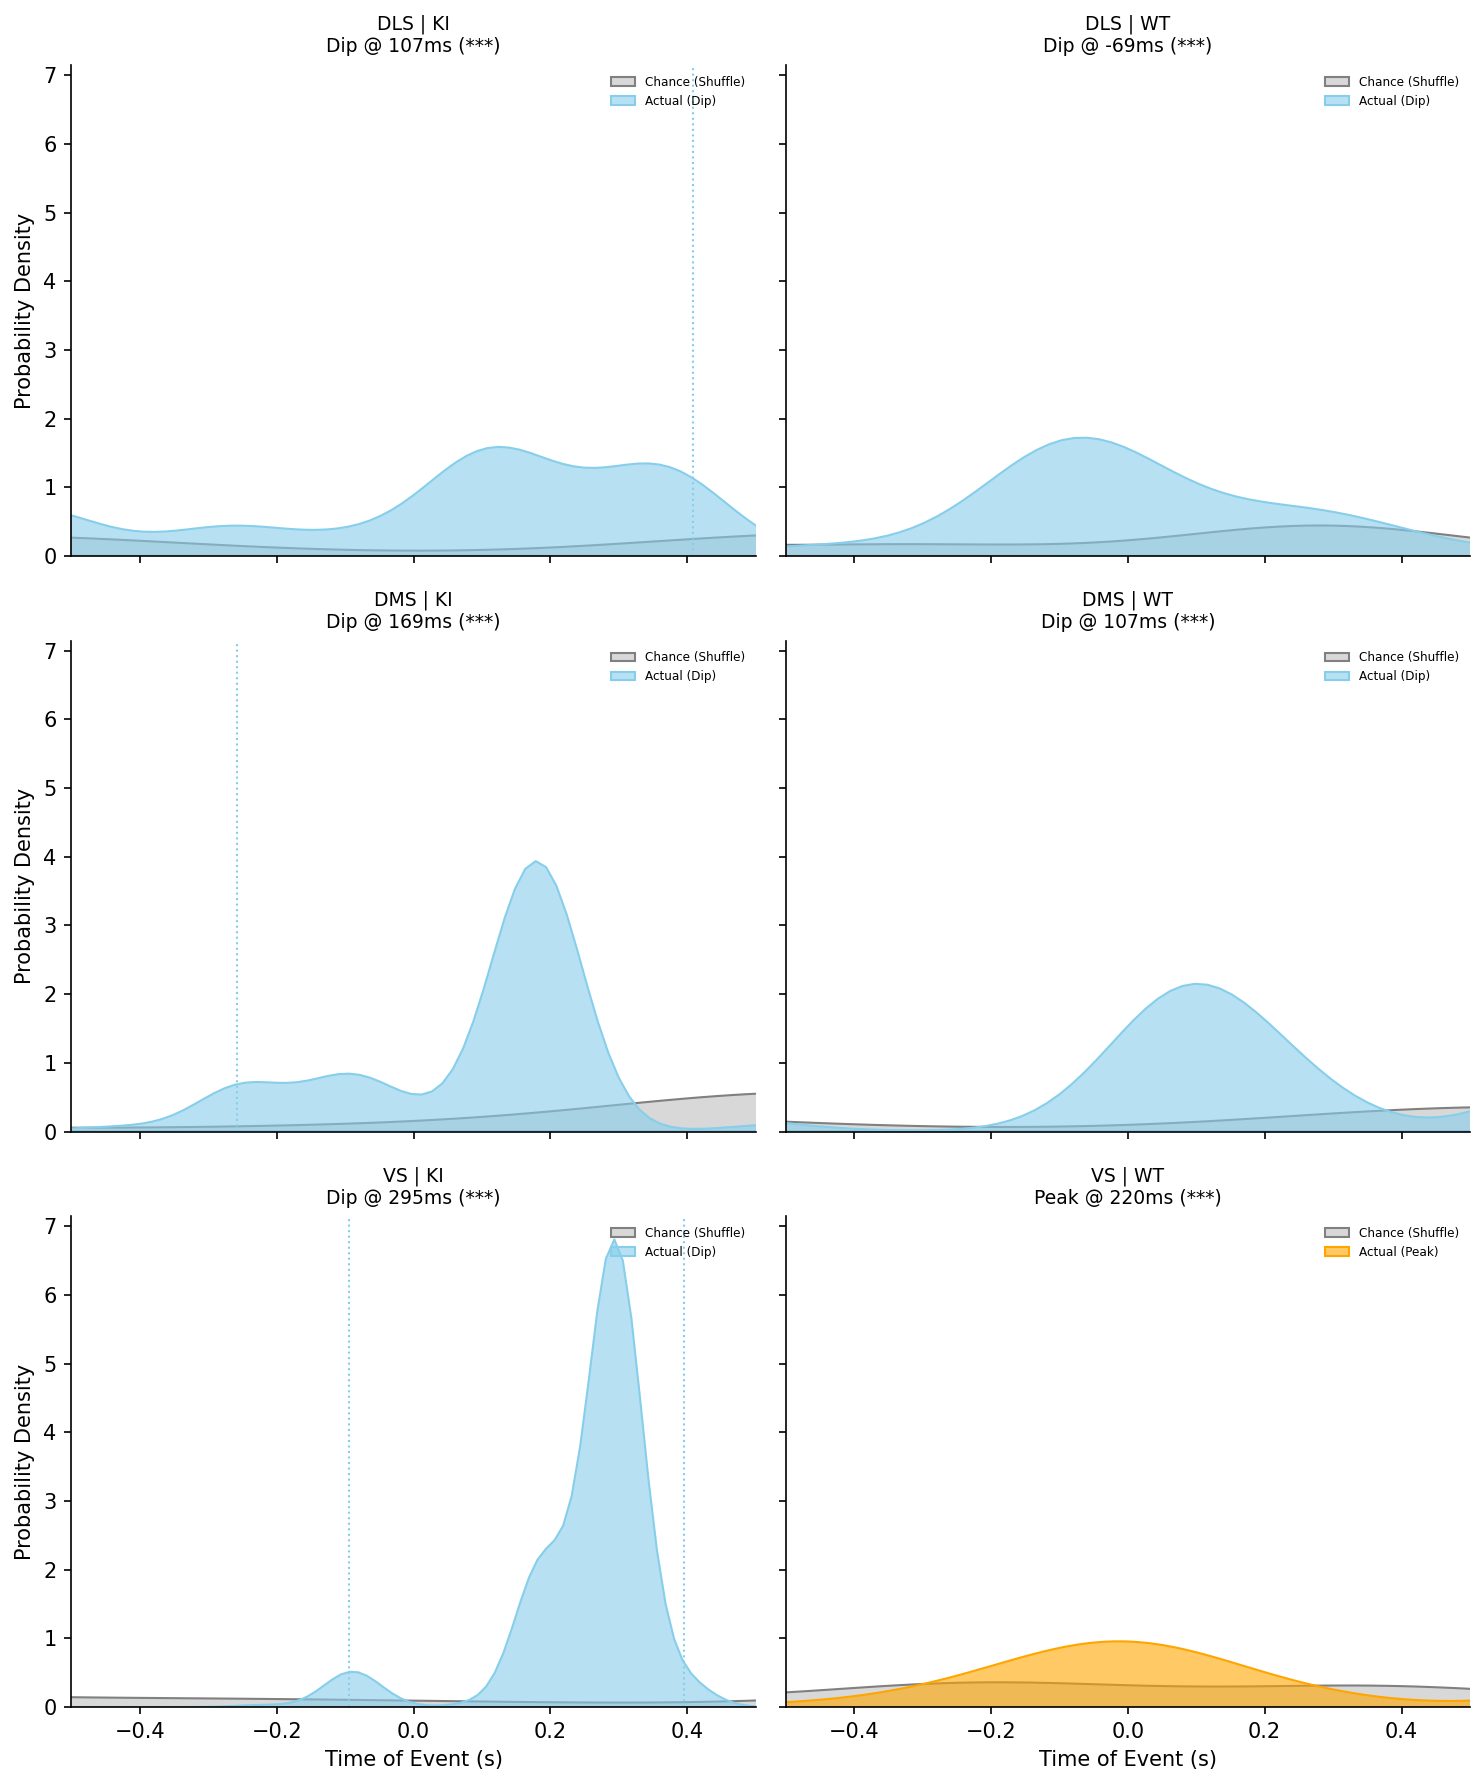


=== HYPOTHESIS TEST: Does Onset Predict Peak Timing? ===
Condition       | Type | Peak Time (95% CI)        | KS-Test (vs Chance)
---------------------------------------------------------------------------
DLS|KI          | Dip  | -584ms to 408ms           | p=1.4e-163 (SIGNIFICANT)
DLS|WT          | Dip  | -1487ms to 1149ms         | p=1.5e-156 (SIGNIFICANT)
DMS|KI          | Dip  | -257ms to 960ms           | p=8.2e-119 (SIGNIFICANT)
DMS|WT          | Dip  | -1010ms to 1211ms         | p=5.1e-64 (SIGNIFICANT)
VS|KI           | Dip  | -94ms to 395ms            | p=1.1e-153 (SIGNIFICANT)
VS|WT           | Peak | -1123ms to 1086ms         | p=7.6e-140 (SIGNIFICANT)


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# 1. CONFIGURATION
# ==========================================
N_BOOTSTRAPS = 1000        
CONFIDENCE_LEVEL = 0.95    
WINDOW_SEC = 1.5           
MIN_TRIALS_FOR_STATS = 100 

# ==========================================
# 2. BOOTSTRAP ANALYSIS (Actual vs Shuffle)
# ==========================================
print(f"Running {N_BOOTSTRAPS} bootstraps (Actual vs Null)...")

results = {} 

unique_genos = sorted(data_buckets.keys())
unique_regions = sorted({r for g in data_buckets for r in data_buckets[g]})

fig, axes = plt.subplots(
    nrows=len(unique_regions), ncols=len(unique_genos), 
    figsize=(5 * len(unique_genos), 4 * len(unique_regions)),
    dpi=150, sharex=True, sharey=True
)

if len(unique_regions) == 1 and len(unique_genos) == 1: axes = np.array([[axes]])
elif len(unique_regions) == 1: axes = axes[np.newaxis, :]
elif len(unique_genos) == 1: axes = axes[:, np.newaxis]

for r_idx, region in enumerate(unique_regions):
    for c_idx, geno in enumerate(unique_genos):
        ax = axes[r_idx, c_idx]
        syll_data = data_buckets[geno].get(region, {})
        
        if not syll_data:
            ax.text(0.5, 0.5, "No Data", ha='center', va='center'); continue

        # --- A. POOL TRACES ---
        pool_actual = []
        pool_shuffle = [] # We need the shuffle pool to build the Null Distribution
        
        for syll, session_list in syll_data.items():
            total_trials = sum(item[0] for item in session_list)
            if total_trials < MIN_TRIALS_FOR_STATS: continue
            
            # Reconstruct Global Averages for this syllable
            weighted_actual = np.zeros_like(session_list[0][1])
            weighted_shuffle = np.zeros_like(session_list[0][2])
            
            for n, act, shuff in session_list:
                weighted_actual += act * n
                weighted_shuffle += shuff * n
            
            pool_actual.append(weighted_actual / total_trials)
            pool_shuffle.append(weighted_shuffle / total_trials)
            
        if not pool_actual:
            ax.text(0.5, 0.5, "No valid syllables", ha='center', va='center'); continue
            
        arr_actual = np.array(pool_actual)
        arr_shuffle = np.array(pool_shuffle)
        n_sylls, n_time = arr_actual.shape
        time_vec = np.linspace(-WINDOW_SEC, WINDOW_SEC, n_time)
        
        # --- B. BOOTSTRAP PEAK TIMES ---
        peaks_actual = []
        peaks_null = []
        
        for _ in range(N_BOOTSTRAPS):
            # Resample indices
            idx = np.random.choice(n_sylls, n_sylls, replace=True)
            
            # 1. Actual Distribution (Where does the real signal peak?)
            mean_act = np.mean(arr_actual[idx], axis=0)
            pk_act = np.argmax(np.abs(mean_act)) # Max Abs Value
            peaks_actual.append(time_vec[pk_act])
            
            # 2. Null Distribution (Where does the jittered noise peak?)
            # We bootstrap the SHUFFLE traces. 
            # If "onset predicts peak", Actual should be clustered at 0, Null should be random.
            mean_shuff = np.mean(arr_shuffle[idx], axis=0)
            pk_null = np.argmax(np.abs(mean_shuff))
            peaks_null.append(time_vec[pk_null])
            
        peaks_actual = np.array(peaks_actual)
        peaks_null = np.array(peaks_null)
        
        # --- C. STATISTICS (KS-Test) ---
        # Test if the two distributions are different
        ks_stat, ks_p = stats.ks_2samp(peaks_actual, peaks_null)
        
        # Calculate CI for Actual
        ci_low = np.percentile(peaks_actual, 2.5)
        ci_high = np.percentile(peaks_actual, 97.5)
        med_peak = np.median(peaks_actual)
        
        # Determine Direction (Peak vs Dip) based on the median trace value at peak
        grand_mean_trace = np.mean(arr_actual, axis=0)
        peak_idx_global = np.argmax(np.abs(grand_mean_trace))
        direction = "Peak" if grand_mean_trace[peak_idx_global] > 0 else "Dip"
        
        results[f"{region}|{geno}"] = (ci_low, ci_high, ks_p, direction)
        
        # --- D. VISUALIZATION ---
        # Null Hypothesis (Gray)
        sns.kdeplot(peaks_null, ax=ax, color="gray", fill=True, alpha=0.3, label="Chance (Shuffle)")
        
        # Actual Data (Color)
        color = "orange" if direction == "Peak" else "skyblue"
        sns.kdeplot(peaks_actual, ax=ax, color=color, fill=True, alpha=0.6, label=f"Actual ({direction})")
        
        # CI Lines
        ax.axvline(ci_low, color=color, linestyle=":", linewidth=1)
        ax.axvline(ci_high, color=color, linestyle=":", linewidth=1)
        
        # Stats Title
        sig_star = "***" if ks_p < 0.001 else ("**" if ks_p < 0.01 else ("*" if ks_p < 0.05 else "n.s."))
        ax.set_title(f"{region} | {geno}\n{direction} @ {med_peak*1000:.0f}ms ({sig_star})", fontsize=9)
        
        if c_idx == 0: ax.set_ylabel("Probability Density")
        if r_idx == len(unique_regions)-1: ax.set_xlabel("Time of Event (s)")
        
        ax.set_xlim(-0.5, 0.5)
        ax.legend(loc='upper right', fontsize='xx-small', frameon=False)
        sns.despine(ax=ax)

plt.tight_layout()
plt.show()

# --- REPORT ---
print(f"\n=== HYPOTHESIS TEST: Does Onset Predict {direction} Timing? ===")
print(f"{'Condition':<15} | {'Type':<4} | {'Peak Time (95% CI)':<25} | {'KS-Test (vs Chance)'}")
print("-" * 75)

for key, (low, high, p, direct) in results.items():
    time_str = f"{low*1000:.0f}ms to {high*1000:.0f}ms"
    p_str = f"p={p:.1e}" if p < 0.001 else f"p={p:.3f}"
    sig = "SIGNIFICANT" if p < 0.05 else "NOT SIG"
    print(f"{key:<15} | {direct:<4} | {time_str:<25} | {p_str} ({sig})")